# **Arena**

## **Section 1: Setting directory and preparing the dataset**

In [ ]:
%pip install -q torch==2.10.0 torchvision==0.25.0 --index-url https://download.pytorch.org/whl/cu128

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 166.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 246.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 223.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 49.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 74.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 99.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 111.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 117.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 116.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 99.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 113.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.1/139.1 MB 143.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
%%capture
!pip install torchmetrics
!pip install pkbar
!pip install calflops
!pip install torchinfo
!pip install grad-cam

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Drive Directory**

In [ ]:
import os
import zipfile
import json
import pandas as pd
import numpy as np
import random as rd
import shutil
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torchvision
from torchvision.transforms import v2, InterpolationMode
import timm
import calflops
from functools import partial

In [ ]:
drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
dataset_name = 'MushroomA'
dataset_drive_dir = f'{drive_dir}/data/{dataset_name}'

model_name_path = 'convnext_tiny_224_r1_v3' # เปลี่ยนเสมอ
model_name = 'ConvNeXt-Tiny' # เปลี่ยนเสมอ
sigle_model_title = f'{model_name} on {dataset_name} Dataset'
ensemble_model_title = f'{model_name} Ensemble on {dataset_name} Dataset'
model_dir = os.path.join(drive_dir, f'modelWeights/{dataset_name}', f"{model_name_path}_{dataset_name}")
model_ensem_dir = f'{model_dir}/ensemble'
model_summary_dir = f'{model_dir}/summary'

os.makedirs(model_dir, exist_ok=True)
font_dir = f'{drive_dir}/assets/fonts'

os.chdir(f'{drive_dir}')
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


**Runtime Directory**

In [ ]:
import src.reproducibility as reproducibility
import src.utils as utils
import src.datasets as datasets
import src.train as train
import src.test as test
import src.visualization as visualization
import src.gradCam as gradCam
import models.models as models

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')
def callbacks_fn(n_fold, fold_dir):
    checkpoint_path = f'{fold_dir}/{model_name_path}_{dataset_name}_best_weight.pth'
    return [utils.ModelCheckpoint(save_path=checkpoint_path, monitor=train.train_config['monitor'], mode=train.train_config['monitor_mode'])]

/usr/local/lib/python3.13/dist-packages/pkbar/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [ ]:
runtime_dir = '/content'
dataset_dir = f'{runtime_dir}/{dataset_name}'
os.makedirs(dataset_dir, exist_ok=True)

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on {device}.')
!python3 --version
!nvidia-smi

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Running on cuda.
Python 3.13.15
Mon Oct  5 11:32:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   48C    P8             16W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         | 

**Load data from G-Drive**

In [ ]:
with zipfile.ZipFile(f'{dataset_drive_dir}/{dataset_name}_SPLIT_KEEP_DUP.zip', 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

remain_classes = set(os.listdir(f'{dataset_dir}/remain'))
test_classes = set(os.listdir(f'{dataset_dir}/test'))
unique_classes = remain_classes.union(test_classes)
NUM_CLASSES = len(unique_classes)
print(f'Number of classes: {NUM_CLASSES}')
print(f'Dataset has been extracted to {dataset_dir}')

Number of classes: 9
Dataset has been extracted to /content/MushroomA


## **Section 2: Define model architecture**

In [ ]:
model_fn = partial(
    models.build_baseline_model,
    model_name=model_name,
    num_classes=NUM_CLASSES,
    device=device,
    freeze_backbone=False
)
model = model_fn()

criterion = nn.CrossEntropyLoss()
optimizer_fn = lambda m : optim.AdamW(m.parameters(), lr=train.train_config['base_lr'], weight_decay=train.train_config['weight_decay'])
scheduler_fn = partial(optim.lr_scheduler.CosineAnnealingLR, T_max=train.train_config['max_epochs'])

model_config = models.get_transform_config(model)
summary(model, (1,) + model_config['input_size'], device=device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Layer (type:depth-idx)                             Output Shape              Param #
ConvNeXt                                           [1, 9]                    --
├─Sequential: 1-1                                  [1, 96, 56, 56]           --
│    └─Conv2d: 2-1                                 [1, 96, 56, 56]           4,704
│    └─LayerNorm2d: 2-2                            [1, 96, 56, 56]           192
├─Sequential: 1-2                                  [1, 768, 7, 7]            --
│    └─ConvNeXtStage: 2-3                          [1, 96, 56, 56]           --
│    │    └─Identity: 3-1                          [1, 96, 56, 56]           --
│    │    └─Sequential: 3-2                        [1, 96, 56, 56]           237,888
│    └─ConvNeXtStage: 2-4                          [1, 192, 28, 28]          --
│    │    └─Sequential: 3-3                        [1, 192, 28, 28]          74,112
│    │    └─Sequential: 3-4                        [1, 192, 28, 28]          918,144
│    └─ConvNeXtSt

## **Section 3: Preparing the dataset**

**Configuration for training**

In [ ]:
img_size = model_config['img_size']
resize_size = int(img_size[0] / model_config['crop_pct'])
interp_mode = getattr(InterpolationMode, model_config['interpolation'].upper())
num_workers = min(4, os.cpu_count())

print(f'Image size: {img_size}')
print(f'Resize size: {resize_size}')
print(f'Interpolation mode: {interp_mode}')
print(f'Number of workers: {num_workers}')

reproducibility.global_seed(seed=train.train_config['seed'])
reproducibility.training_seed(seed=train.train_config['seed'])
g = reproducibility.get_generator(seed=train.train_config['seed'])

Image size: (224, 224)
Resize size: 256
Interpolation mode: InterpolationMode.BICUBIC
Number of workers: 4
Global Seed set to: 42
Training Seed set to: 42


In [ ]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(img_size, scale=(0.08, 1.0), interpolation=interp_mode),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandAugment(num_ops=2, magnitude=6, interpolation=interp_mode),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std']),
    v2.RandomErasing(p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False)
])

transform = v2.Compose([
    v2.Resize(resize_size, interpolation=interp_mode, max_size=None, antialias=True),
    v2.CenterCrop(img_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std'])
])

dataloader_kwargs = {
    'batch_size': train.train_config['batch_size'],
    'num_workers': num_workers,
    'worker_init_fn': reproducibility.seed_worker,
    'generator': g,
    'pin_memory': True
}

datasets = datasets.Datasets(
    dataset_dir=dataset_dir,
    train_transform=train_transform,
    transform=transform,
    dataloader_kwargs=dataloader_kwargs,
)

datasets.print_summary()
test_loader = datasets.get_test_loader()

--------------------------------------------------
Dataset Summary
--------------------------------------------------
Class names       : ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']
Class to Index    : {'Agaricus': 0, 'Amanita': 1, 'Boletus': 2, 'Cortinarius': 3, 'Entoloma': 4, 'Hygrocybe': 5, 'Lactarius': 6, 'Russula': 7, 'Suillus': 8}
Index to Class    : {0: 'Agaricus', 1: 'Amanita', 2: 'Boletus', 3: 'Cortinarius', 4: 'Entoloma', 5: 'Hygrocybe', 6: 'Lactarius', 7: 'Russula', 8: 'Suillus'}
Total remain data : 5375
Total test data   : 1326
--------------------------------------------------


## **Section 4: Training the model**

In [ ]:
trainer = train.KFoldTrainer(
    n_splits=train.train_config['n_folds'],
    shuffle=True,
    random_state=train.train_config['seed'],
    model_name=model_name_path,
    dataset_name=dataset_name,
    base_dir=model_dir,
    first_metric=train.train_config['first_metric'],
    first_metric_mode=train.train_config['first_metric_mode'],
    secondary_metric=train.train_config['secondary_metric'],
    secondary_metric_mode=train.train_config['secondary_metric_mode'],
    device=device,
    criterion=criterion,
    n_classes=NUM_CLASSES,
    task=train.train_config['task'],
    average=train.train_config['average'],
    max_grad_norm=0.0
)

[Logs] Setup directories at '/content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA' successfully.


In [ ]:
fold_histories = trainer.fit_kfold(
    train_dataset=datasets.train_dataset,
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    model_fn=model_fn,
    optimizer_fn=optimizer_fn,
    epochs=train.train_config['max_epochs'],
    dataloader_kwargs=dataloader_kwargs,
    callbacks_fn=callbacks_fn,
    scheduler_fn=scheduler_fn
)

Starting Stratified 5-Fold Cross Validation

--------------------------------------------- FOLD 1/5 ---------------------------------------------
Epoch: 1/30
135/135 [==============================] - 47s 346ms/step - loss: 1.4422 - lr: 1.0000e-04 - accuracy: 0.5149 - f1: 0.3946 - precision: 0.5818 - recall: 0.3778
Epoch 1/30 | val_loss: 0.7089 - val_accuracy: 0.7805 - val_f1: 0.7154 - val_precision: 0.8066 - val_recall: 0.7025
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.7805, saving model to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/fold_1/convnext_tiny_224_r1_v3_MushroomA_best_weight.pth
Epoch: 2/30
135/135 [==============================] - 39s 291ms/step - loss: 0.6186 - lr: 9.9726e-05 - accuracy: 0.8016 - f1: 0.7662 - precision: 0.7977 - recall: 0.7468
Epoch 2/30 | val_loss: 0.3312 - val_accuracy: 0.8949 - val_f1: 0.8761 - val_precision: 0.9187 - val_recall: 0.8513
[Logs] Epoch: 2 val_accuracy improved from 0.7805 to 0

## **Section 5: Individual model performance**

In [ ]:
y_true = test.get_true_label(test_loader, is_onehot=False)

### **Learning curve**

#### **Individual**

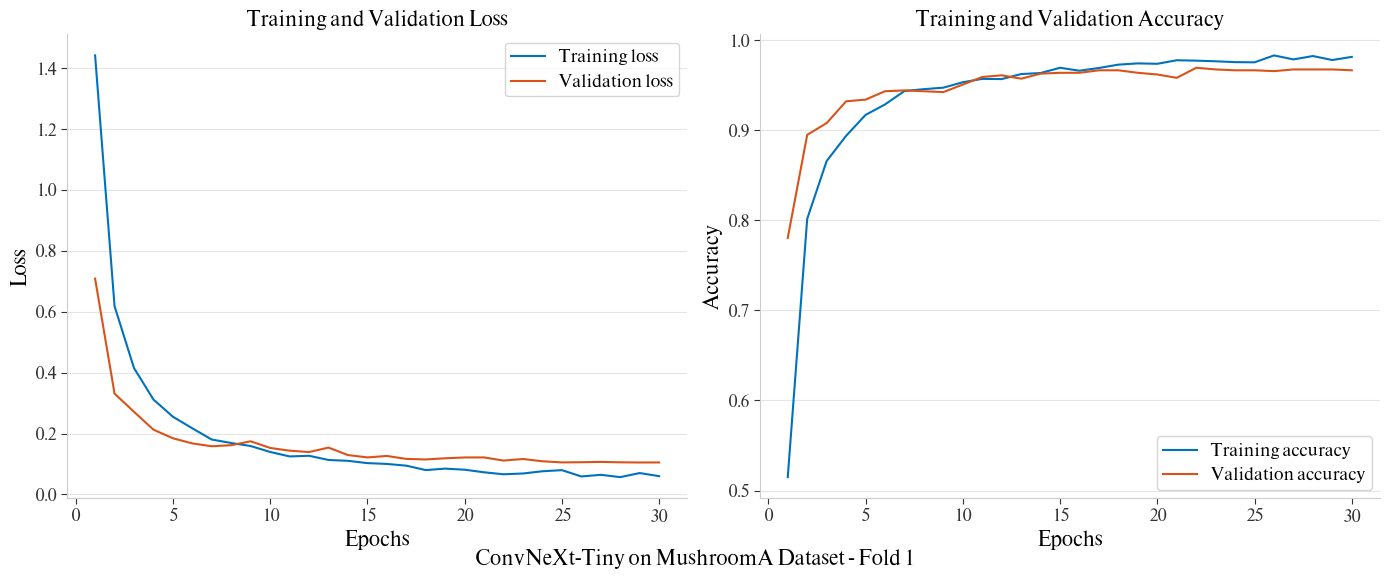

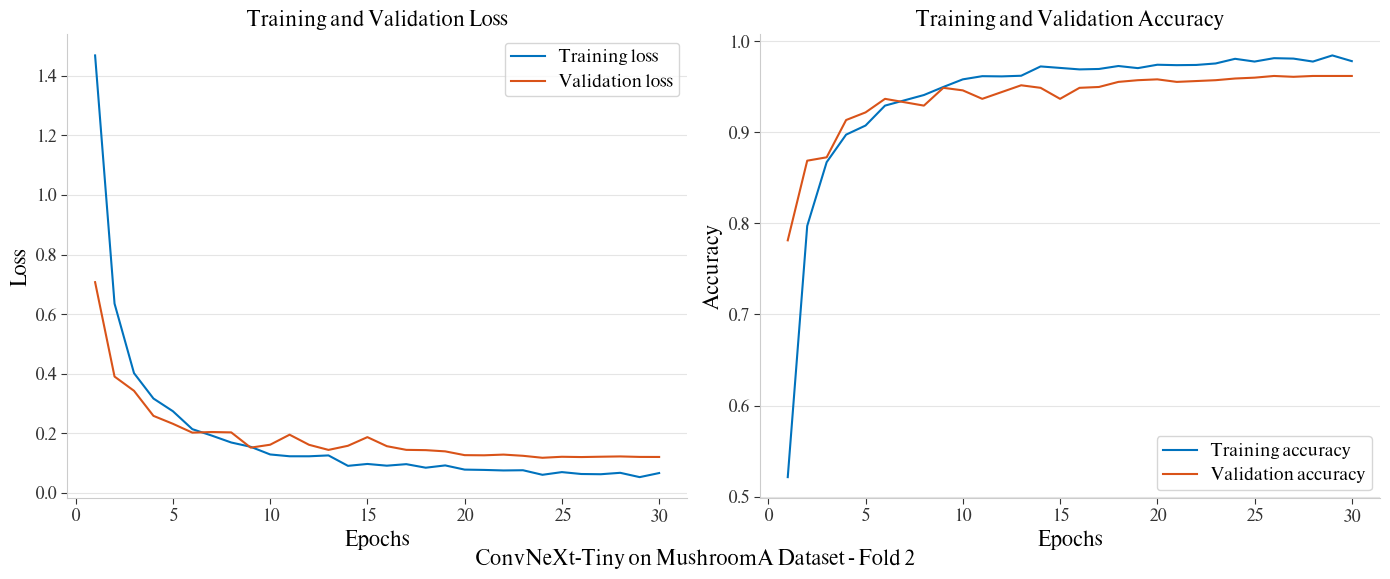

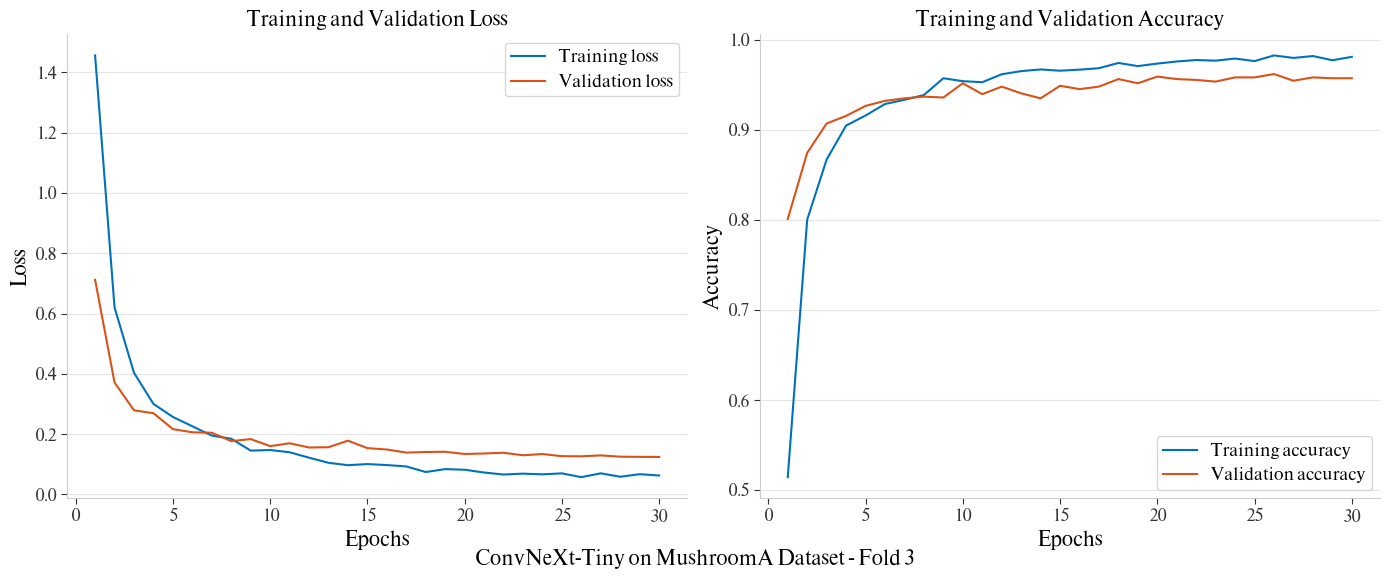

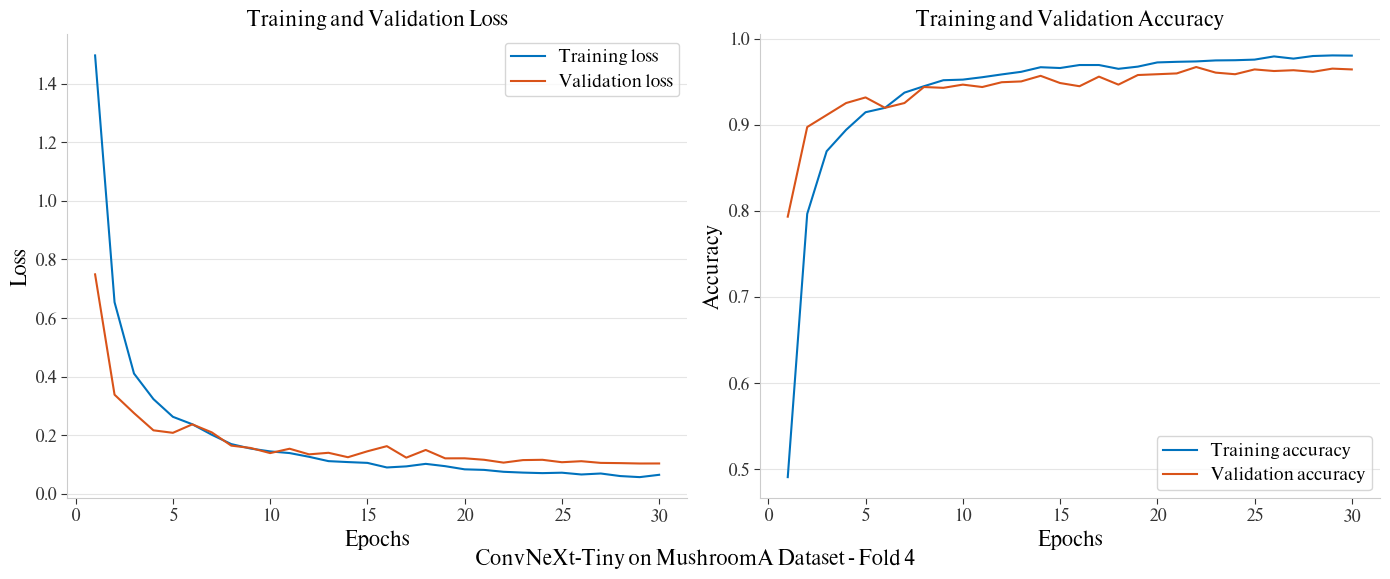

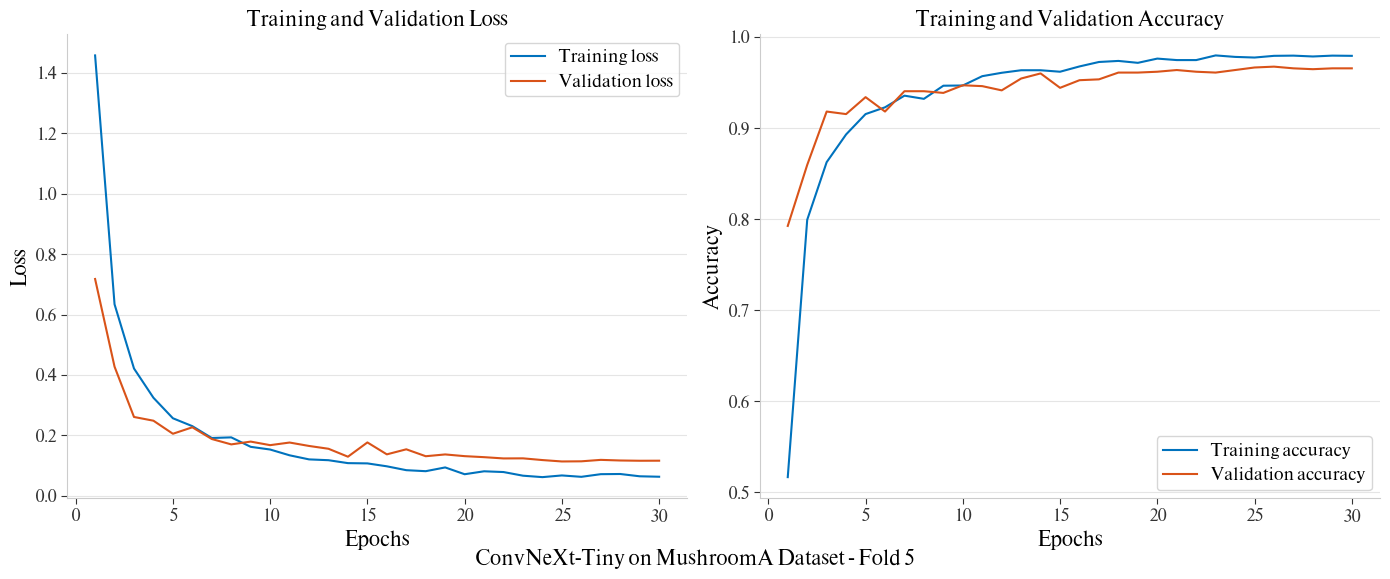

In [ ]:
for fold_key, history in fold_histories.items():
    fold_num = fold_key.split('_')[1]
    fold_dir = f"{trainer.base_dir}/fold_{fold_num}"

    visualization.plot_lr_curve(
        history=history,
        figsize=(14, 6),
        fontsize=14,
        title=f"{sigle_model_title} - Fold {fold_num}",
        save_path=fold_dir
    )

    print('\n')

#### **Overall**

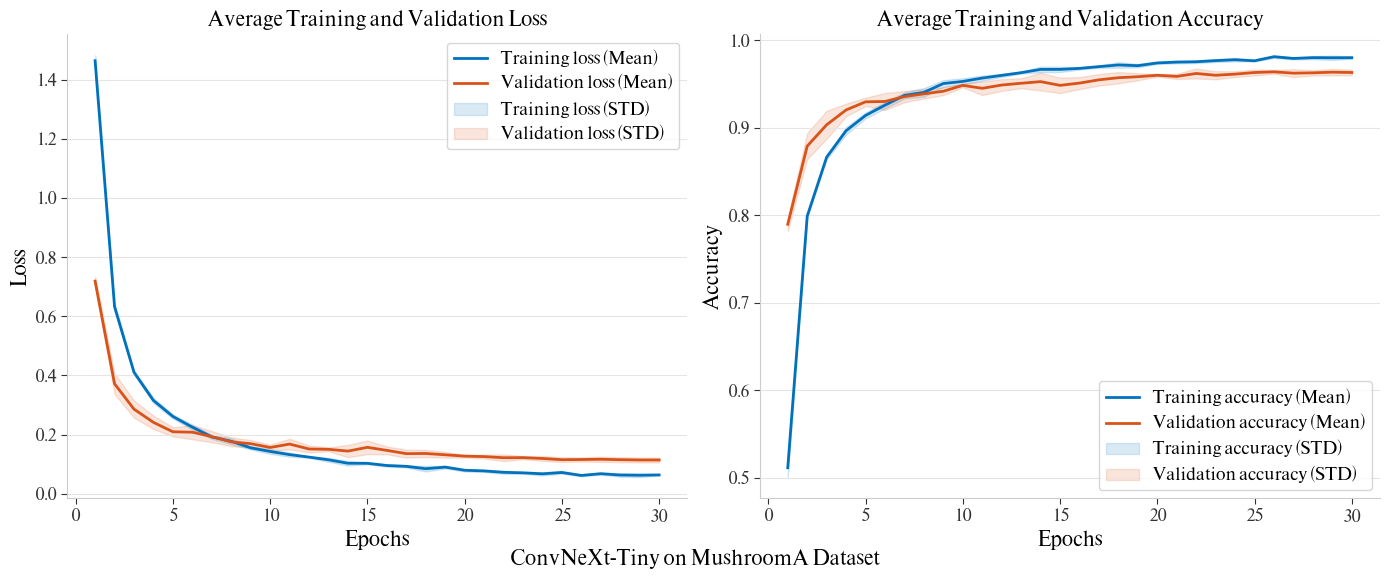

In [ ]:
visualization.plot_cv_summary_curve(
    histories=list(fold_histories.values()),
    figsize=(14, 6),
    fontsize=14,
    title=sigle_model_title,
    save_path=model_ensem_dir
)

### **On validation set**

In [ ]:
individual_validate_perf_df = trainer.evaluate_kfold(
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    dataloader_kwargs=dataloader_kwargs,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type']
)

Evaluating 5-Fold Models on their respective Validation Sets (BEST weights)

[*] Evaluating Fold 1/5 on its Validation Set...
34/34 [==============================] - 4s 109ms/step - loss: 0.1113 - accuracy: 0.9693 - f1: 0.9674 - precision: 0.9700 - recall: 0.9652
[*] Evaluating Fold 2/5 on its Validation Set...
34/34 [==============================] - 4s 106ms/step - loss: 0.1204 - accuracy: 0.9619 - f1: 0.9572 - precision: 0.9588 - recall: 0.9564
[*] Evaluating Fold 3/5 on its Validation Set...
34/34 [==============================] - 4s 108ms/step - loss: 0.1264 - accuracy: 0.9619 - f1: 0.9517 - precision: 0.9581 - recall: 0.9461
[*] Evaluating Fold 4/5 on its Validation Set...
34/34 [==============================] - 4s 109ms/step - loss: 0.1068 - accuracy: 0.9674 - f1: 0.9663 - precision: 0.9663 - recall: 0.9668
[*] Evaluating Fold 5/5 on its Validation Set...
34/34 [==============================] - 4s 105ms/step - loss: 0.1142 - accuracy: 0.9674 - f1: 0.9630 - precision: 0.9696 

### **On test set**

In [ ]:
ensemble_probs, timing_report = trainer.predict_kfold(
    dataloader=test_loader,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type'],
    timer_report_dict=True,
    verbose=1
)

Ensemble Prediction using 5-Fold Models (BEST weights)

[*] Running inference for Fold 1/5...
42/42 [==============================] - 6s 153ms/step

[Inference Report] Latency: 103.99 ms/batch | Throughput: 303.60 samples/sec
    -> Saved fold 1 timing report to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/fold_1/fold_1_infer_timing_report.csv
    -> Saved fold 1 predictions to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/fold_1/fold_1_test_probs_best_weight.csv
[*] Running inference for Fold 2/5...
42/42 [==============================] - 4s 107ms/step

[Inference Report] Latency: 56.01 ms/batch | Throughput: 563.70 samples/sec
    -> Saved fold 2 timing report to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/fold_2/fold_2_infer_timing_report.csv
    -> Saved fold 2 predictions to /content/drive/MyDrive/projectMushroom/modelWeights/Mu

In [ ]:
individual_test_perf_df = test.evaluate_preds_kfold(
    base_dir=model_dir,
    n_splits=train.train_config['n_folds'],
    y_true=y_true,
    weight_type=train.train_config['weight_type'],
    task=train.train_config['task'],
    average=train.train_config['average'],
)

[*] Fold 1/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 2/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 3/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 4/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 5/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro

----------------------------------------------------------------------------------------------------
K-Fold Test Set Evaluation Results (Individual Models):
  Fold     loss  accuracy       f1  precision   recall
Fold 1 0.136878  0.957014 0.954498   0.958025 0.951399
Fold 2 0.131628  0.956259 0.951865   0.955213 0.948798
Fold 3 0.124523  0.960784 0.958985   0.964311 0.954016
Fold 4 0.118496  0.960030 0.957129   0.955759 0.958633
Fold 5 0.127045  0.957768 0.955175   0.961080 0.949698
  Mean 0.127714  0.958371 0.955530   0.958878 0.952509
   STD 0.006980  0.001952 0.002698   0.003816 0.003959
---------------------------

## **Section 6: Ensemble model performance**

### **On test set**

In [ ]:
y_pred, metrics = test.evaluate_preds(
    y_true=y_true,
    y_probs=ensemble_probs,
    task=train.train_config['task'],
    average=train.train_config['average'],
    save_path=f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv'
)

[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble/ensem_test_perf_best_weight.csv


### **Classification report**

In [ ]:
report = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name)

report_dict = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(f'{model_ensem_dir}/ensem_classification_report.csv')

print('Classification Report on Ensemble')
print('=' * 100)
print(report)

Classification Report on Ensemble
              precision    recall  f1-score   support

    Agaricus     0.9853    0.9571    0.9710        70
     Amanita     0.9797    0.9667    0.9732       150
     Boletus     0.9906    0.9906    0.9906       213
 Cortinarius     0.9763    0.9880    0.9821       167
    Entoloma     0.9859    0.9589    0.9722        73
   Hygrocybe     1.0000    0.9841    0.9920        63
   Lactarius     0.9668    0.9700    0.9684       300
     Russula     0.9485    0.9693    0.9588       228
     Suillus     0.9508    0.9355    0.9431        62

    accuracy                         0.9729      1326
   macro avg     0.9760    0.9689    0.9724      1326
weighted avg     0.9730    0.9729    0.9729      1326



### **Correct predictions**

In [ ]:
df_correct, df_incorrect = test.pred_records(
    y_true=y_true,
    y_pred=y_pred,
    y_probs=ensemble_probs,
    filepaths=[path for path, _ in test_loader.dataset.samples],
    idx_to_class=datasets.idx_to_class,
    save_dir=f'{model_ensem_dir}',
    prefix='ensem'
)

In [ ]:
df_correct

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Agaricus/001_2jP9N_ipA...,Agaricus,Agaricus,0,0,0.993706
1,/content/MushroomA/test/Agaricus/016_qNYODERZE...,Agaricus,Agaricus,0,0,0.999224
2,/content/MushroomA/test/Agaricus/027_-CwuQDPSh...,Agaricus,Agaricus,0,0,0.951503
3,/content/MushroomA/test/Agaricus/028_-vDPakMKn...,Agaricus,Agaricus,0,0,0.998871
4,/content/MushroomA/test/Agaricus/042_qk77X1_g0...,Agaricus,Agaricus,0,0,0.998920
...,...,...,...,...,...,...
1285,/content/MushroomA/test/Suillus/291_JvaBBYqBgB...,Suillus,Suillus,8,8,0.767465
1286,/content/MushroomA/test/Suillus/297_XQdw8OtzxL...,Suillus,Suillus,8,8,0.980801
1287,/content/MushroomA/test/Suillus/308_KjxkhQlHYr...,Suillus,Suillus,8,8,0.976028
1288,/content/MushroomA/test/Suillus/311_MfqUejCCW5...,Suillus,Suillus,8,8,0.993166


### **Incorrect predictions**

In [ ]:
df_incorrect

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Agaricus/320_ebYxJS43T...,Amanita,Agaricus,1,0,0.843049
1,/content/MushroomA/test/Agaricus/333_LwsnJQC9r...,Entoloma,Agaricus,4,0,0.931957
2,/content/MushroomA/test/Agaricus/354_VP-DWvLyI...,Amanita,Agaricus,1,0,0.990891
3,/content/MushroomA/test/Amanita/386_1CH7OWFK1z...,Russula,Amanita,7,1,0.929353
4,/content/MushroomA/test/Amanita/437_TI-chUFr6Z...,Russula,Amanita,7,1,0.373868
5,/content/MushroomA/test/Amanita/475_3-LU-M6jSU...,Russula,Amanita,7,1,0.983834
6,/content/MushroomA/test/Amanita/536_xGjRHkFDGS...,Suillus,Amanita,8,1,0.396360
7,/content/MushroomA/test/Amanita/725_IybD3vqx0z...,Russula,Amanita,7,1,0.721202
8,/content/MushroomA/test/Boletus/0654_S0ZETeWMB...,Suillus,Boletus,8,2,0.887586
9,/content/MushroomA/test/Boletus/0789_HeUlbr2dI...,Suillus,Boletus,8,2,0.700213


### **Confusion matrix**

#### **without Normalize**

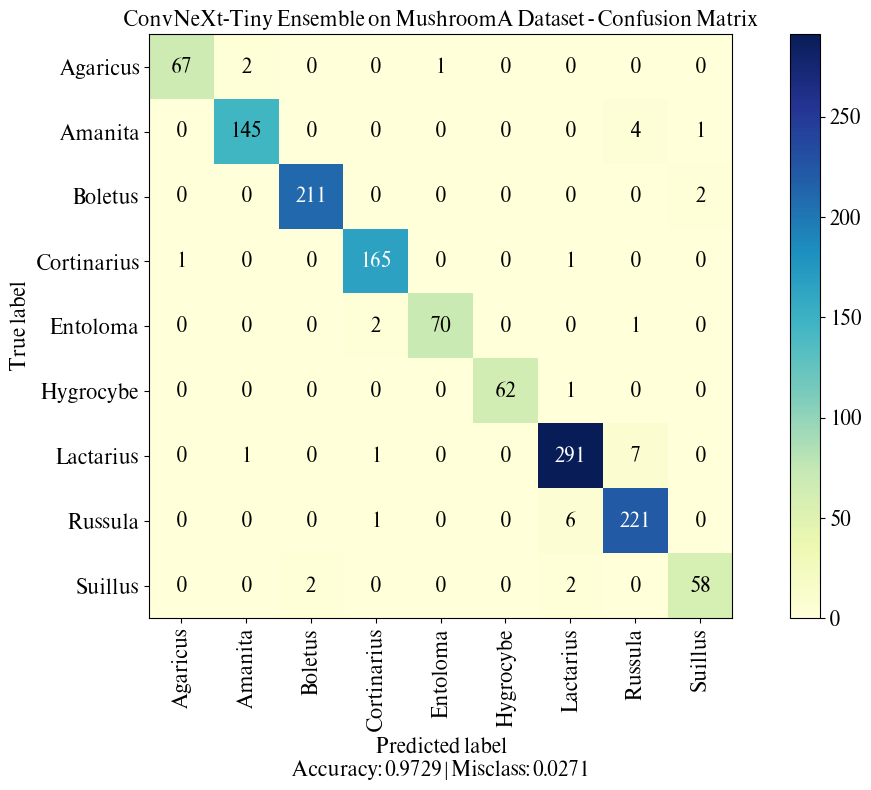

In [ ]:
cm = confusion_matrix(y_true, y_pred)
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=False,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 8),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

#### **with Normalize**

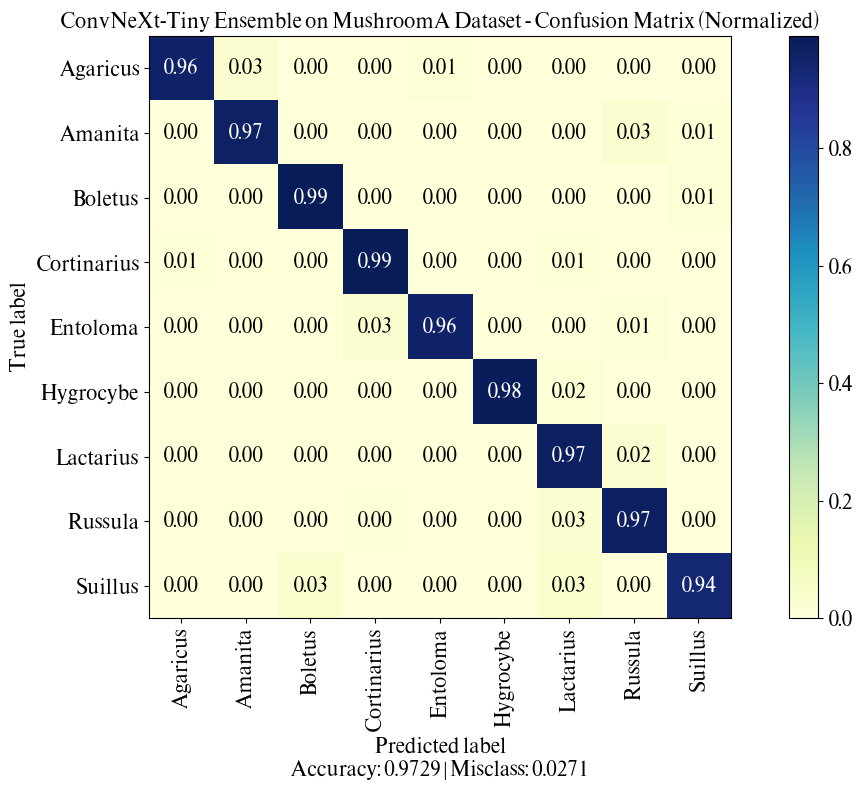

In [ ]:
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=True,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 8),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

### **ROC-AUC curve**

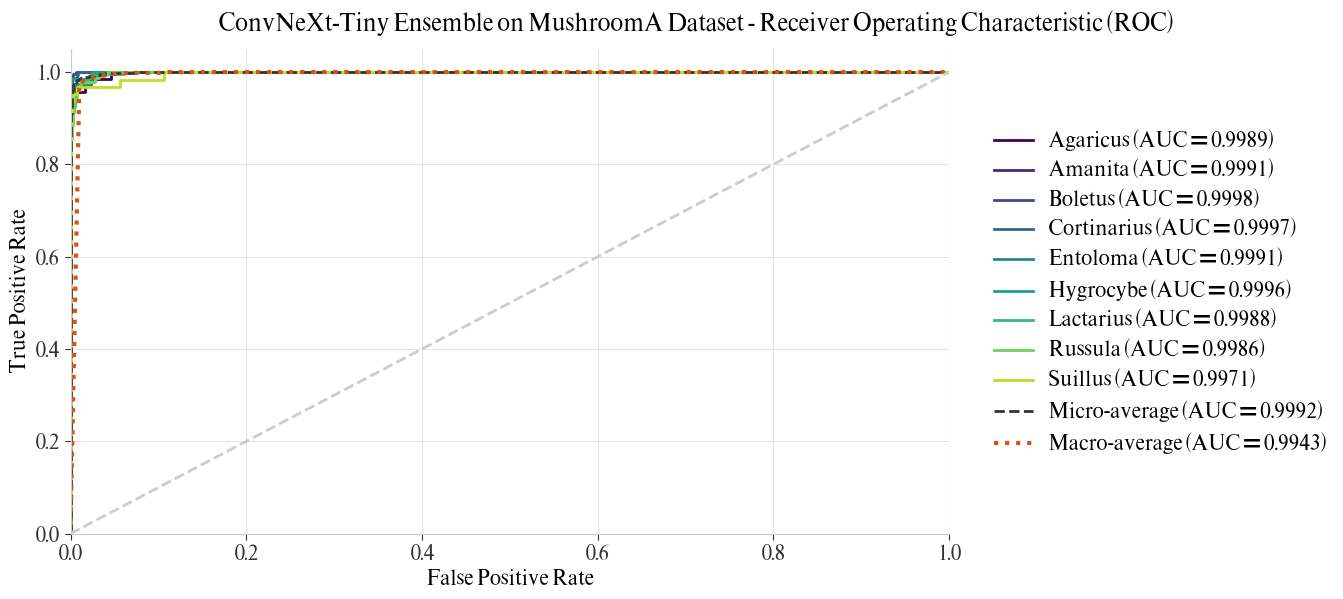

In [ ]:
visualization.plot_roc_auc_curve(
    y_true=y_true,
    y_pred_probs=ensemble_probs,
    class_names=datasets.classes_name,
    task=train.train_config['task'],
    legend_ncol=1,
    figsize=(14, 6),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

## **Section 7: Grad-CAM**

In [ ]:
best_model, best_fold_dir, best_fold_num = trainer.get_best_model_on_validate_set(model_fn=model_fn)
target_layers = [best_model.stages[-1].blocks[-1]]
print(target_layers)

[Logs] Retrieving Best Model from Fold 1
       Primary Metric: accuracy->0.9693 | Secondary: loss->0.1113 on Validation set.
[ConvNeXtBlock(
  (conv_dw): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU()
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (shortcut): Identity()
  (drop_path): Identity()
)]


In [ ]:
unique_label = pd.read_csv(f'{dataset_drive_dir}/unique_label.csv')
unique_label

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Entoloma/385_3iniw1mVk...,Entoloma,Entoloma,4,4,0.970201
1,/content/MushroomA/test/Boletus/0993_YMPWY3nZZ...,Boletus,Boletus,2,2,0.991539
2,/content/MushroomA/test/Lactarius/310_MVmkt2VW...,Lactarius,Lactarius,6,6,0.986088
3,/content/MushroomA/test/Amanita/290_8VTdQ2j5LL...,Amanita,Amanita,1,1,0.999764
4,/content/MushroomA/test/Russula/433_P89n7ud6bL...,Russula,Russula,7,7,0.999470
5,/content/MushroomA/test/Cortinarius/540_r5xzAI...,Cortinarius,Cortinarius,3,3,0.998794
6,/content/MushroomA/test/Agaricus/351_mHFbGn8oQ...,Agaricus,Agaricus,0,0,0.999605
7,/content/MushroomA/test/Hygrocybe/172_o-_VYiEs...,Hygrocybe,Hygrocybe,5,5,0.998320
8,/content/MushroomA/test/Suillus/231__NpqweN7Eq...,Suillus,Suillus,8,8,0.997972


In [ ]:
gradCam.plot_grad_cam(
    model=best_model,
    target_layers=target_layers,
    df=unique_label,
    filepaths_col='Filepaths',
    true_label_col='True_Label',
    true_idx='True_Index',
    device=device,
    transform=transform,
    task=train.train_config['task'],
    reshape_transform=None,
    img_size=model_config['img_size'],
    img_base_size=3,
    row_one_title=True,
    fontsize=24,
    save_path=model_ensem_dir,
    titlesize=24
)

Output hidden; open in https://colab.research.google.com to view.

## **Section 8: Summary**

##### **Performace on Validation Set (N Folds)**

In [ ]:
display(individual_validate_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.111272,0.969302,0.967389,0.969964,0.965206
Fold 2,0.120438,0.961860,0.957226,0.958831,0.956430
Fold 3,0.126367,0.961860,0.951698,0.958116,0.946122
Fold 4,0.106781,0.967442,0.966261,0.966264,0.966781
Fold 5,0.114198,0.967442,0.963020,0.969624,0.956902
Mean,0.115811,0.965581,0.961119,0.964560,0.958288
STD,0.007707,0.003481,0.006582,0.005747,0.008267


##### **Performace on Test Set (N Folds)**

In [ ]:
display(individual_test_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.136878,0.957014,0.954498,0.958025,0.951399
Fold 2,0.131628,0.956259,0.951865,0.955213,0.948798
Fold 3,0.124523,0.960784,0.958985,0.964311,0.954016
Fold 4,0.118496,0.960030,0.957129,0.955759,0.958633
Fold 5,0.127045,0.957768,0.955175,0.961080,0.949698
Mean,0.127714,0.958371,0.955530,0.958878,0.952509
STD,0.006980,0.001952,0.002698,0.003816,0.003959


##### **Performace on Test Set (Ensemble)**

In [ ]:
ensem_test_perf_df = pd.read_csv(f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv')
display(ensem_test_perf_df.style.hide(axis="index"))

loss,accuracy,f1,precision,recall
0.101654,0.972851,0.972378,0.975997,0.968917


#### **Model Info**

In [ ]:
flops, macs, params = calflops.calculate_flops(
    model=best_model,
    input_shape=(1,) + model_config['input_size'],
    output_precision=4,
    print_results=False
)

flops_val = float(flops.split()[0])
if 'MFLOPS' in flops:
    flops_val /= 1000.0
flops = f'{flops_val:.4f}'

macs_val = float(macs.split()[0])
if 'MMACs' in macs:
    macs_val /= 1000.0
macs = f'{macs_val:.4f}'

params_val = float(params.split()[0])
if 'K' in params:
    params_val /= 1000.0
elif 'B' in params:
    params_val *= 1000.0
params = f'{params_val:.4f}'

model_summary_report = {
    'Batch Size': [train.train_config['batch_size']],
    'Image Size': [f'{img_size[0]}\u00D7{img_size[1]}'],
    'GFLOPs': [flops],
    'GMACs': [macs],
    'Params (M)': [params],
    'Latency (ms/img)': timing_report['avg_single_model_latency_sample'],
    'Latency (ms/batch)': timing_report['avg_single_model_latency_batch'],
    'Throughput (img/s)': timing_report['avg_single_model_throughput'],
}

model_summary_df = pd.DataFrame(model_summary_report)
model_summary_df.to_csv(f'{model_summary_dir}/model_summary.csv', index=False)
display(model_summary_df.style.hide(axis="index"))

Batch Size,Image Size,GFLOPs,GMACs,Params (M),Latency (ms/img),Latency (ms/batch),Throughput (img/s)
32,224×224,8.9379,4.4548,27.8270,1.773131,55.980277,563.989078


## **Section 9: Addition**

##### **Preparation**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

add_drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
add_dataset_name = 'MushroomA'

def get_model_dir(model_name_path, weights_root='modelWeights', dataset_name=add_dataset_name):
    return os.path.join(add_drive_dir, f'{weights_root}/{dataset_name}', f'{model_name_path}_{dataset_name}')

# Model of this notebook
add_weights_root = 'modelWeights'
add_model_name_path = 'convnext_tiny_224_r1_v3'
add_model_name = 'ConvNeXt-Tiny (Duplicate)'
add_model_dir = get_model_dir(add_model_name_path, weights_root=add_weights_root)

# McNemar's test: Baseline vs Proposed (Default proposed = model of this notebook)
mc_baseline_name = 'ConvNeXt-Tiny (Cleaning)'
mc_baseline_model_dir = get_model_dir('convnext_tiny_224_r1_v1', weights_root='modelWeights')
mc_proposed_name = add_model_name
mc_proposed_model_dir = add_model_dir
mc_alpha = 0.05

add_config = {
    'n_folds': 5,
    'task': 'multiclass',
    'average': 'macro',
    'weight_type': 'best',
}

add_plot_kwargs = {
    'cmap': plt.cm.YlGnBu,
    'fontsize': 14,
}

In [3]:
os.chdir(add_drive_dir)
print(f'Current directory: {os.getcwd()}')
print(f'Model directory   : {add_model_dir}')
print(f'Baseline directory: {mc_baseline_model_dir}')
print(f'Proposed directory: {mc_proposed_model_dir}')

import src.visualization as visualization
import src.ensembleVoting as ensembleVoting
import src.mcnemarTest as mcnemarTest

visualization.matplotlib_font(font_dir=f'{add_drive_dir}/assets/fonts', prefer_name='Times-Roman')

Current directory: /content/drive/MyDrive/projectMushroom
Model directory   : /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA
Baseline directory: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v1_MushroomA
Proposed directory: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA


'OPTITimes-Roman'

##### **Compare voting strategies on test set**

[*] Loaded Fold 1/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 2/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 3/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 4/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 5/5 probabilities | Shape: (1326, 9)
[*] Recovered test order verified against /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble/ensem_test_probs_best_weight.csv
[*] Recovered 1326 test samples | 9 classes
[Logs] Saved Voting Weights to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble_addition/voting_weights_best_weight.csv

Voting Method: SOFT
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble_addition/soft/soft_test_perf_best_weight.csv
              precision    recall  f1-score   support

    Agaricus     0.9853    0.9571    0.9

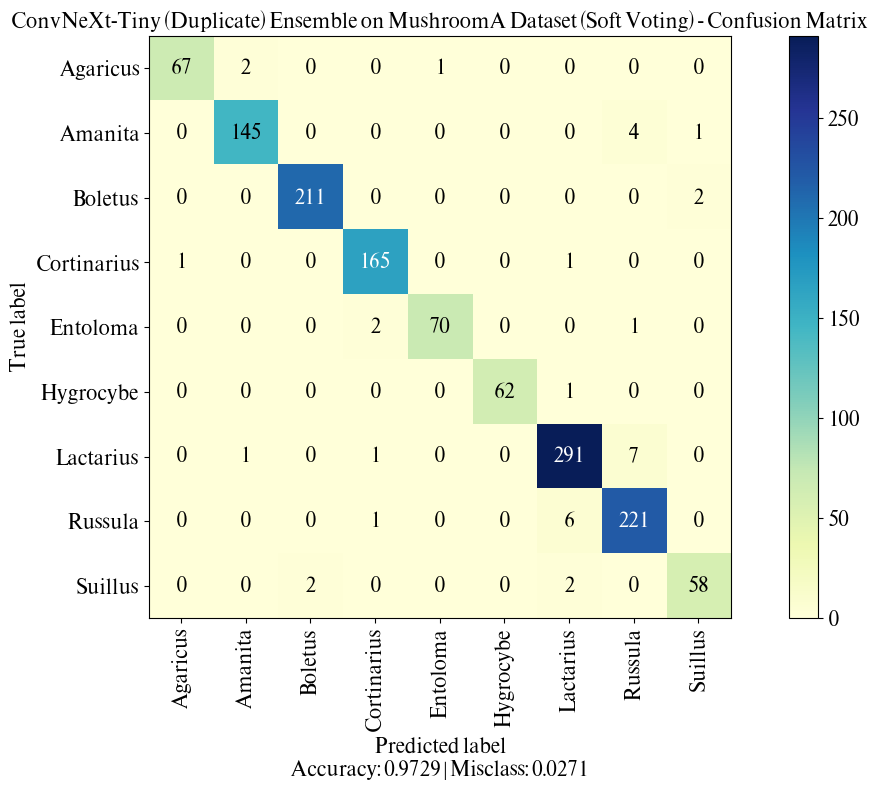

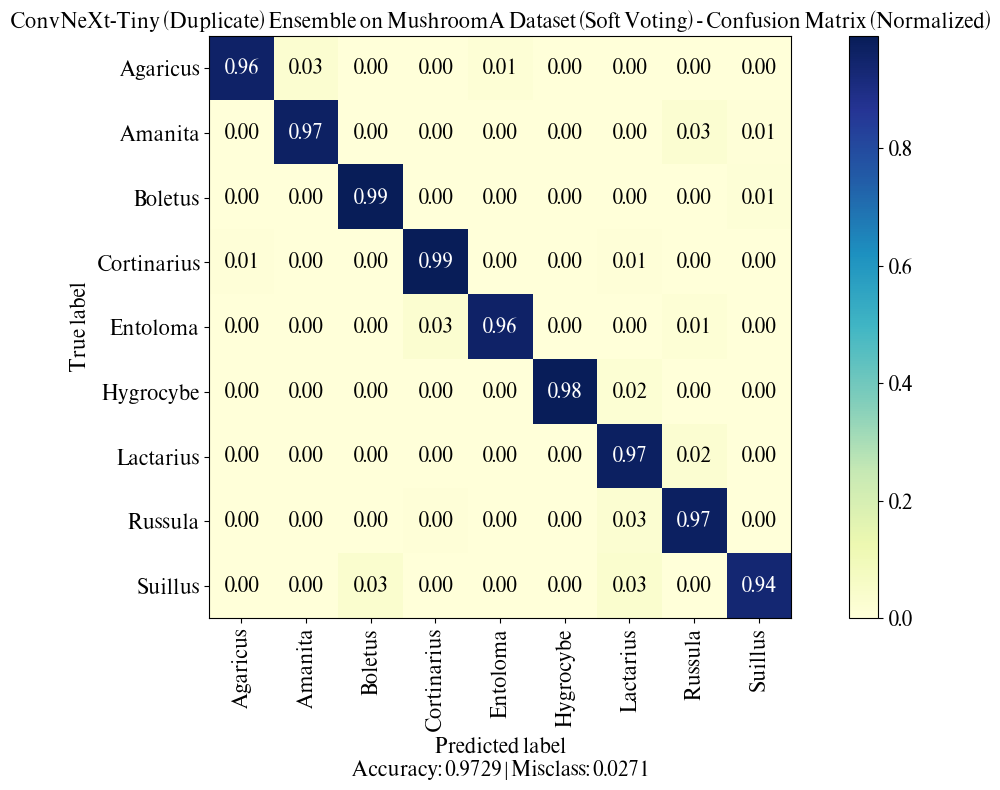

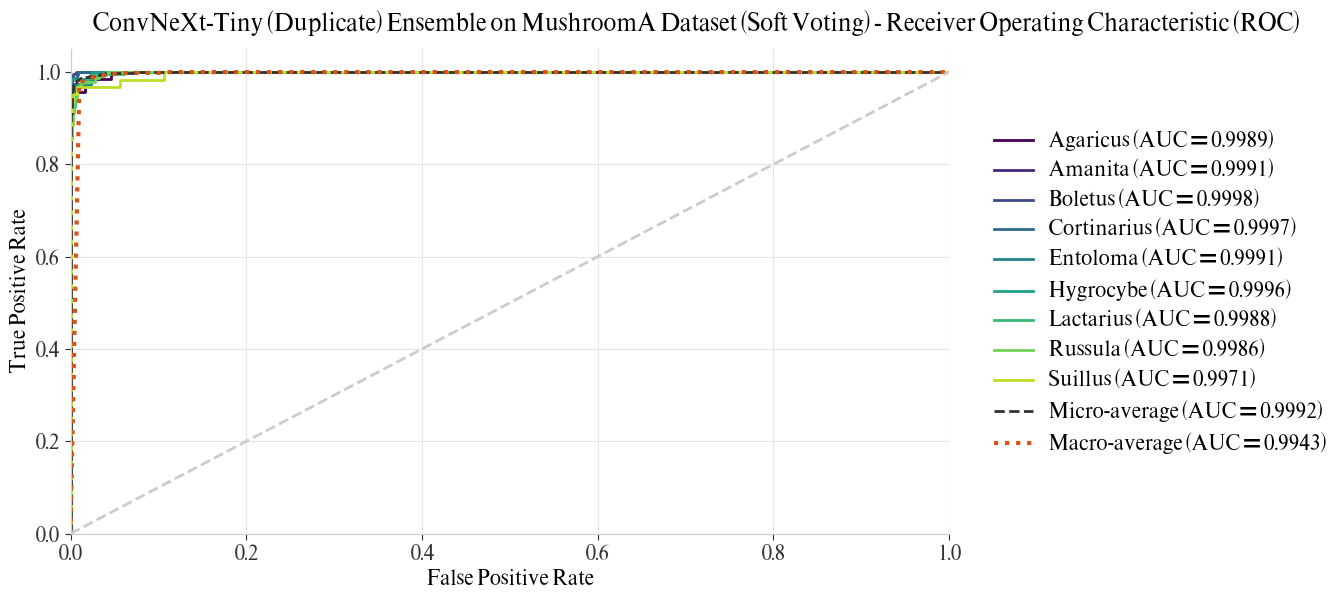




Voting Method: HARD
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble_addition/hard/hard_test_perf_best_weight.csv
              precision    recall  f1-score   support

    Agaricus     0.9710    0.9571    0.9640        70
     Amanita     0.9799    0.9733    0.9766       150
     Boletus     0.9906    0.9906    0.9906       213
 Cortinarius     0.9763    0.9880    0.9821       167
    Entoloma     0.9718    0.9452    0.9583        73
   Hygrocybe     1.0000    0.9841    0.9920        63
   Lactarius     0.9700    0.9700    0.9700       300
     Russula     0.9485    0.9693    0.9588       228
     Suillus     0.9667    0.9355    0.9508        62

    accuracy                         0.9729      1326
   macro avg     0.9750    0.9681    0.9715      1326
weighted avg     0.9730    0.9729    0.9728      1326



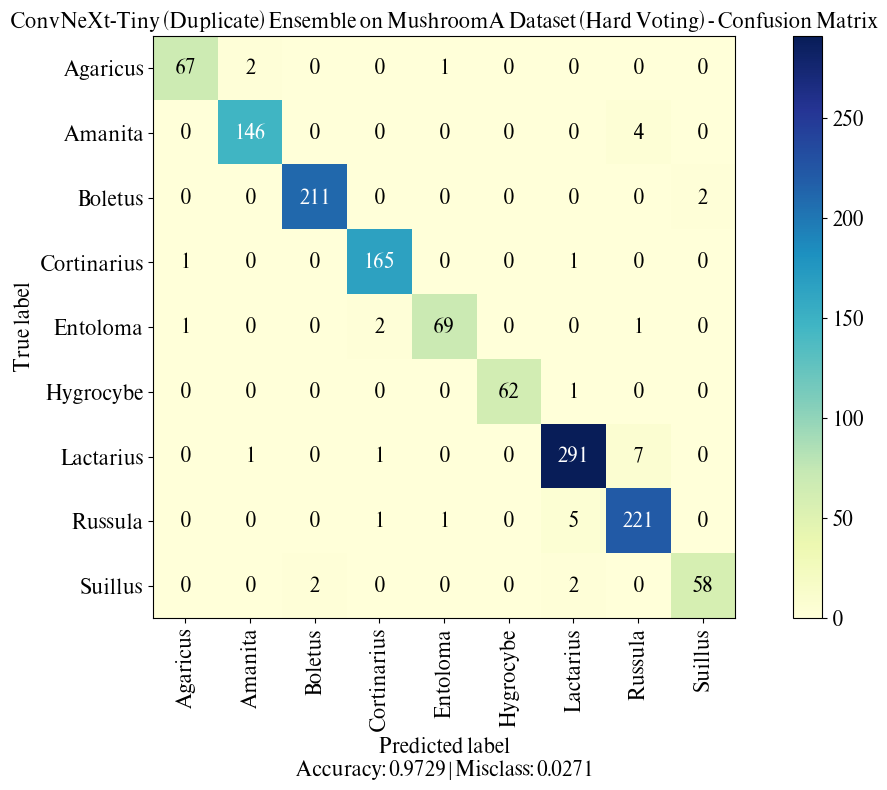

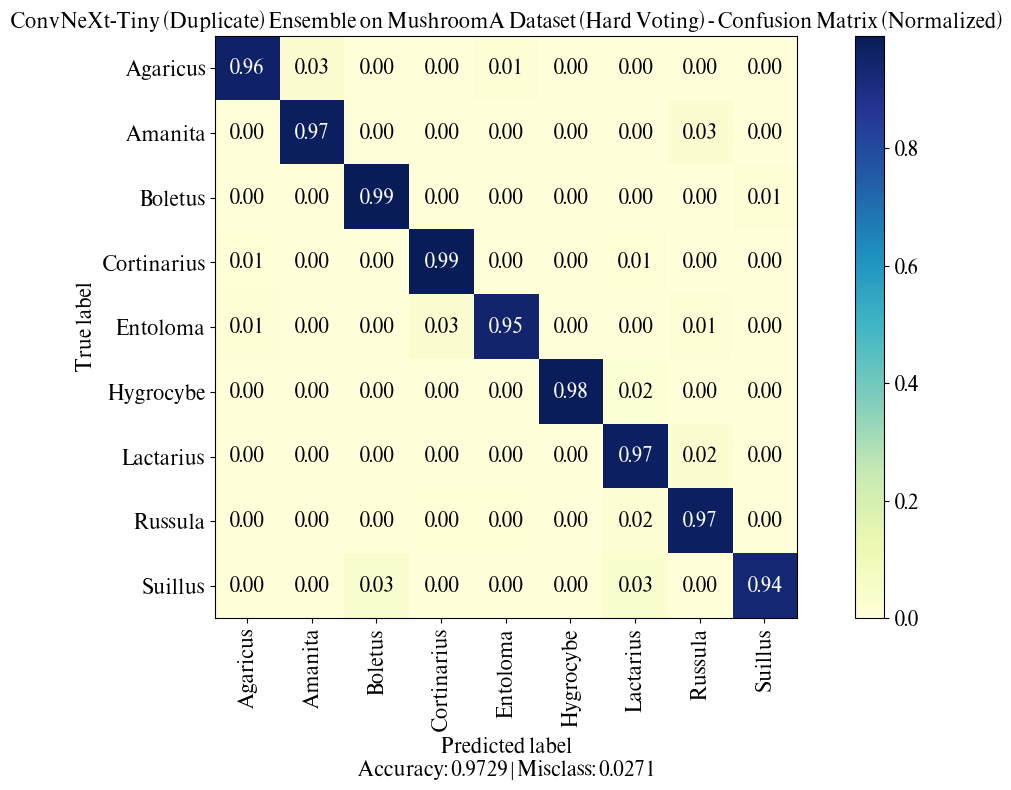




Voting Method: WEIGHTED
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble_addition/weighted/weighted_test_perf_best_weight.csv
              precision    recall  f1-score   support

    Agaricus     0.9853    0.9571    0.9710        70
     Amanita     0.9797    0.9667    0.9732       150
     Boletus     0.9906    0.9906    0.9906       213
 Cortinarius     0.9763    0.9880    0.9821       167
    Entoloma     0.9859    0.9589    0.9722        73
   Hygrocybe     1.0000    0.9841    0.9920        63
   Lactarius     0.9668    0.9700    0.9684       300
     Russula     0.9485    0.9693    0.9588       228
     Suillus     0.9508    0.9355    0.9431        62

    accuracy                         0.9729      1326
   macro avg     0.9760    0.9689    0.9724      1326
weighted avg     0.9730    0.9729    0.9729      1326



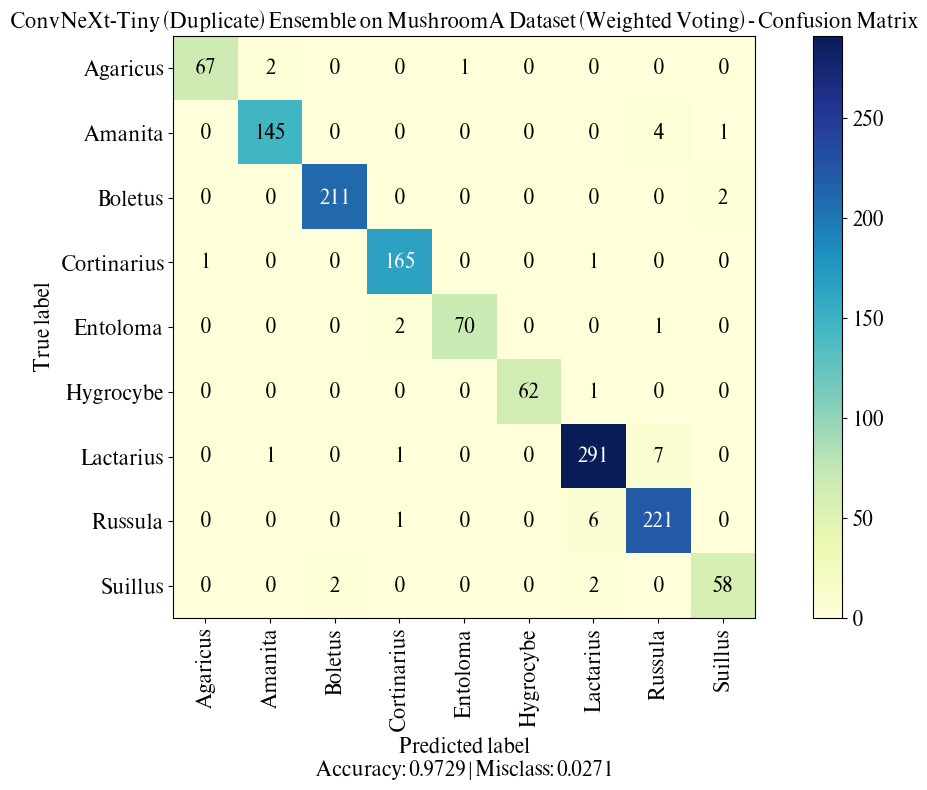

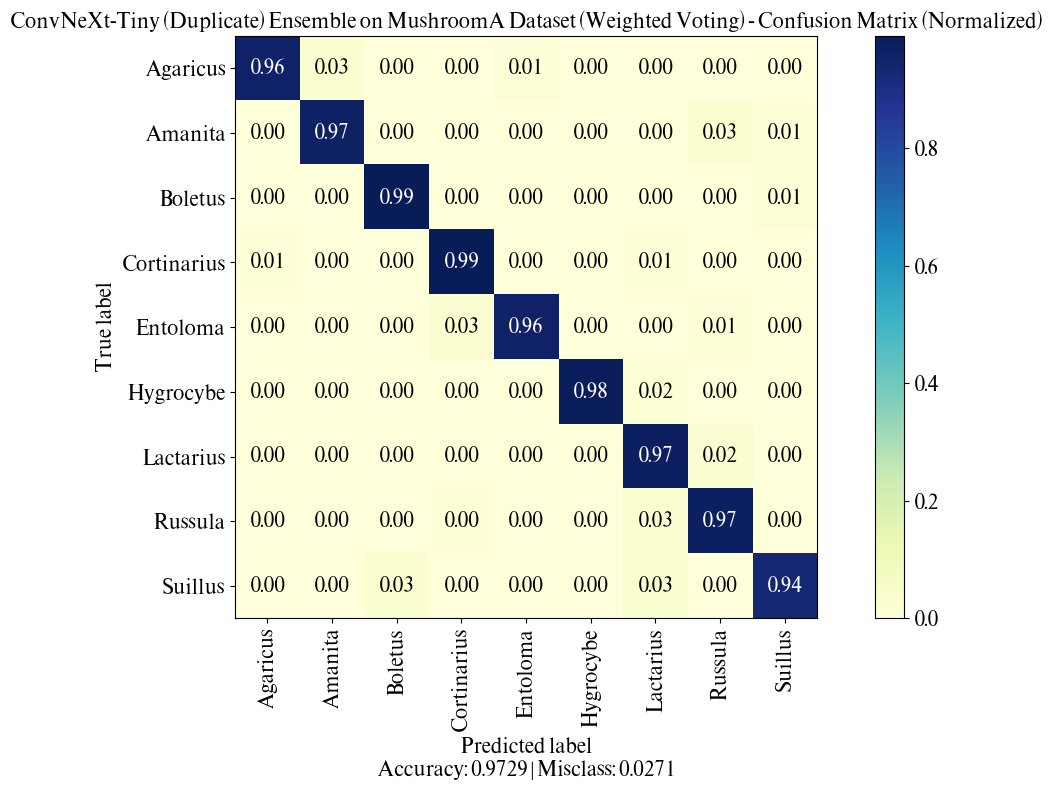

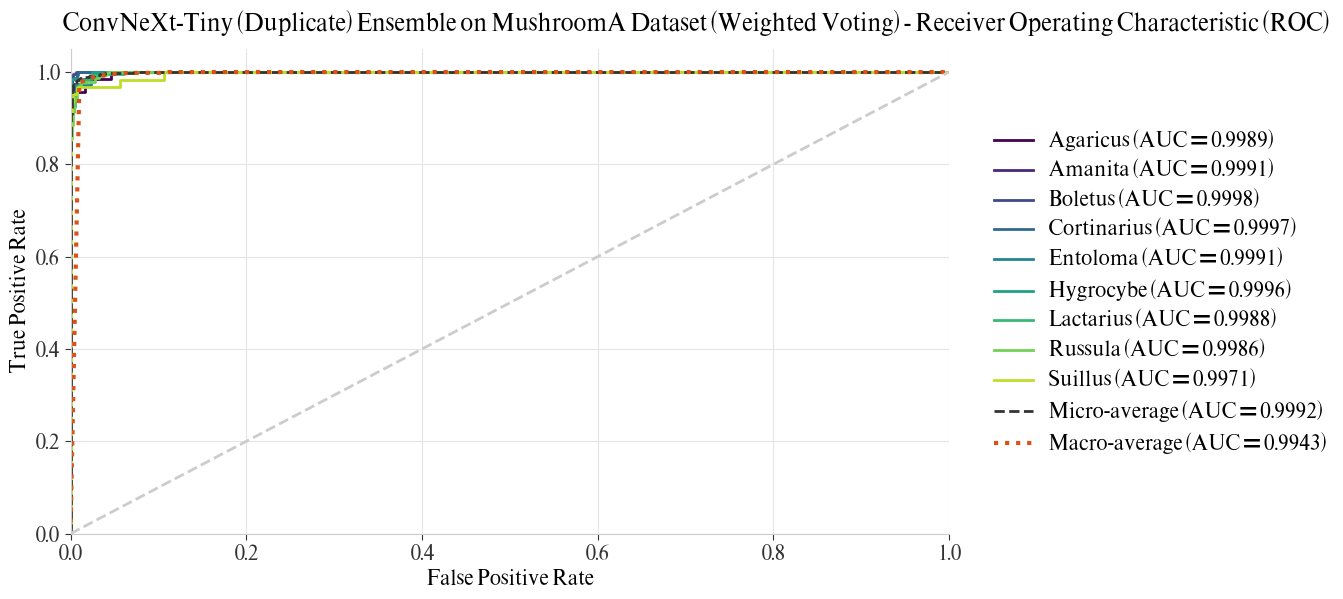




----------------------------------------------------------------------------------------------------
Ensemble Voting Comparison on Test Set (5 models):
         Method     loss  accuracy       f1  precision   recall  n_models  Aggregation Latency (ms/img)  Inference Latency (ms/img)  Total Latency (ms/img)
    Soft Voting 0.101654  0.972851 0.972378   0.975997 0.968917         5                      0.000060                    8.865655                8.865714
    Hard Voting      NaN  0.972851 0.971479   0.974980 0.968136         5                      0.000403                    8.865655                8.866058
Weighted Voting 0.101651  0.972851 0.972378   0.975997 0.968917         5                      0.000134                    8.865655                8.865789
----------------------------------------------------------------------------------------------------
[Logs] Saved Voting Comparison to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3

In [4]:
voting_comparison_df, voting_results = ensembleVoting.compare_voting_strategies(
    base_dir=add_model_dir,
    n_splits=add_config['n_folds'],
    weight_type=add_config['weight_type'],
    task=add_config['task'],
    average=add_config['average'],
    title=f'{add_model_name} Ensemble on {add_dataset_name} Dataset',
    cm_figsize=(12, 8),
    roc_figsize=(14, 6),
    **add_plot_kwargs,
)

##### **Voting weights (from validation accuracy)**

In [5]:
voting_weights_df = pd.read_csv(f"{add_model_dir}/ensemble_addition/voting_weights_{add_config['weight_type']}_weight.csv")
display(voting_weights_df.style.hide(axis="index"))

Fold,val_accuracy,weight
Fold 1,0.969302,0.200771
Fold 2,0.961860,0.199229
Fold 3,0.961860,0.199229
Fold 4,0.967442,0.200385
Fold 5,0.967442,0.200385


##### **Performance on Test Set (Voting comparison, latency in ms/img)**

In [6]:
display(voting_comparison_df.style.hide(axis="index"))

Method,loss,accuracy,f1,precision,recall,n_models,Aggregation Latency (ms/img),Inference Latency (ms/img),Total Latency (ms/img)
Soft Voting,0.101654,0.972851,0.972378,0.975997,0.968917,5,0.000060,8.865655,8.865714
Hard Voting,nan,0.972851,0.971479,0.974980,0.968136,5,0.000403,8.865655,8.866058
Weighted Voting,0.101651,0.972851,0.972378,0.975997,0.968917,5,0.000134,8.865655,8.865789


##### **McNemar's test (Baseline vs Proposed)**

Clean vs Keep Duplicate

[*] Loaded 1326 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v1_MushroomA/ensemble
[*] Loaded 1326 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble
[*] Aligned 1326 test samples (Filepaths and true labels verified)

----------------------------------------------------------------------------------------------------
McNemar's Test: ConvNeXt-Tiny (Duplicate) vs ConvNeXt-Tiny (Cleaning) (N = 1326)
                                     ConvNeXt-Tiny (Cleaning) Correct  ConvNeXt-Tiny (Cleaning) Incorrect
ConvNeXt-Tiny (Duplicate) Correct                                1279                                  11
ConvNeXt-Tiny (Duplicate) Incorrect                                 7                                  29

Chi-square = 0.5000 | p-value = 0.4795 | Exact p-value = 0.4807
alpha = 0.05 -> Fail to reject H0 (no significant difference)
-----------------------------

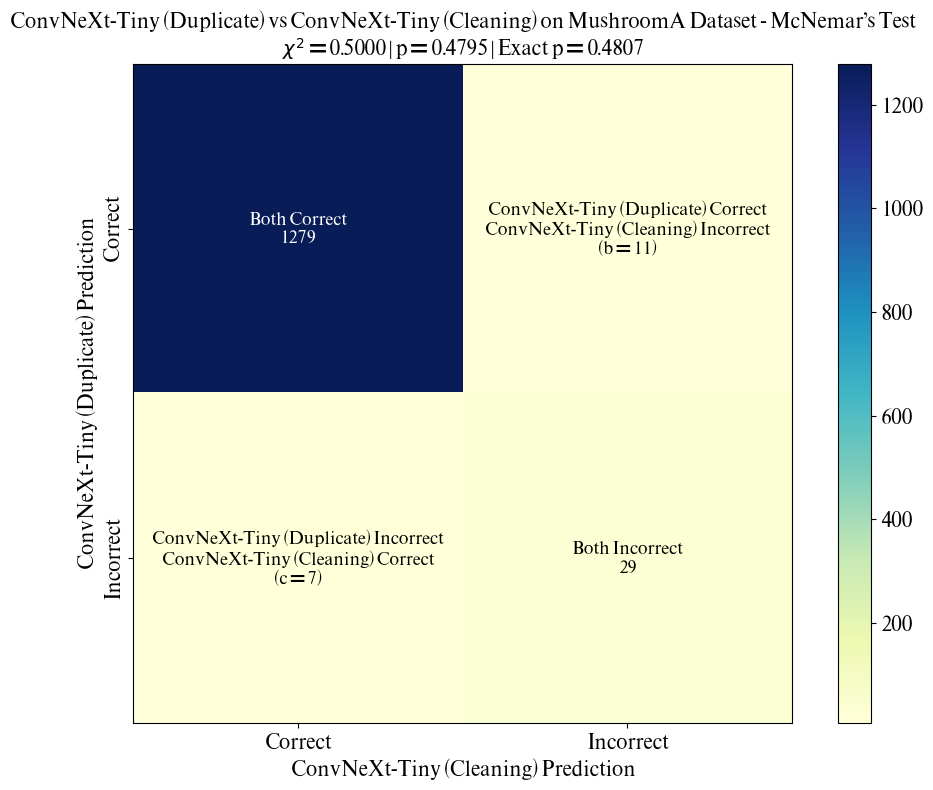

In [7]:
mcnemar_result_df, mcnemar_aligned_df = mcnemarTest.compare_mcnemar(
    baseline_model_dir=mc_baseline_model_dir,
    proposed_model_dir=mc_proposed_model_dir,
    baseline_name=mc_baseline_name,
    proposed_name=mc_proposed_name,
    alpha=mc_alpha,
    title=f'{mc_proposed_name} vs {mc_baseline_name} on {add_dataset_name} Dataset',
    figsize=(10, 8),
    **add_plot_kwargs,
)

##### **McNemar's test result**

In [8]:
display(mcnemar_result_df.style.hide(axis="index"))

Baseline,Proposed,N,Baseline Accuracy,Proposed Accuracy,Accuracy Diff (pp),Both Correct,"b (Proposed Correct, Baseline Incorrect)","c (Proposed Incorrect, Baseline Correct)",Both Incorrect,Chi-square,p-value,Exact p-value,Alpha,Significant
ConvNeXt-Tiny (Cleaning),ConvNeXt-Tiny (Duplicate),1326,0.969834,0.972851,0.301659,1279,11,7,29,0.500000,0.479500,0.480682,0.050000,False


##### **Disagreement samples (Only one model is correct)**

In [9]:
mcnemar_aligned_df[mcnemar_aligned_df['Baseline_Correct'] != mcnemar_aligned_df['Proposed_Correct']]

,Filepaths,True_Index,True_Label,Baseline_Pred_Index,Baseline_Pred_Label,Proposed_Pred_Index,Proposed_Pred_Label,Baseline_Correct,Proposed_Correct
190,/content/MushroomA/test/Amanita/633_h1geqGA79w...,1,Amanita,6,Lactarius,1,Amanita,False,True
453,/content/MushroomA/test/Cortinarius/145_SBd-O-...,3,Cortinarius,1,Amanita,3,Cortinarius,False,True
544,/content/MushroomA/test/Cortinarius/701_5jF8zl...,3,Cortinarius,6,Lactarius,3,Cortinarius,False,True
579,/content/MushroomA/test/Cortinarius/850_3-IUA4...,3,Cortinarius,6,Lactarius,3,Cortinarius,False,True
592,/content/MushroomA/test/Cortinarius/917_MJi5-S...,3,Cortinarius,8,Suillus,3,Cortinarius,False,True
606,/content/MushroomA/test/Entoloma/043_HA9oR2t5g...,4,Entoloma,0,Agaricus,4,Entoloma,False,True
649,/content/MushroomA/test/Entoloma/273_VDgZER3d8...,4,Entoloma,4,Entoloma,7,Russula,True,False
744,/content/MushroomA/test/Lactarius/0026_autPTj6...,6,Lactarius,7,Russula,6,Lactarius,False,True
757,/content/MushroomA/test/Lactarius/0101_GFyNRQO...,6,Lactarius,4,Entoloma,6,Lactarius,False,True
758,/content/MushroomA/test/Lactarius/0107_OQ77ckp...,6,Lactarius,6,Lactarius,7,Russula,True,False


##### **Duplicate Recheck**

In [10]:
# แตกไฟล์ split และโหลด hash group ของภาพซ้ำ
import zipfile
import numpy as np

dup_variant = 'KEEP_DUP'  # variant ของ notebook นี้
clean_model_dir = get_model_dir('convnext_tiny_224_r1_v1', weights_root='modelWeights')  # CLEAN
data_drive_dir = f'{add_drive_dir}/data/{add_dataset_name}'
dup_check_dir = f'{add_model_dir}/ensemble_addition/duplicate_check'
os.makedirs(dup_check_dir, exist_ok=True)

def extract_split(zip_name):
    out_dir = f'/content/dup_check/{zip_name}'
    if not os.path.exists(out_dir):
        with zipfile.ZipFile(f'{data_drive_dir}/{zip_name}.zip', 'r') as zip_ref:
            zip_ref.extractall(out_dir)
    return out_dir

splits = {'CLEAN': extract_split(f'{add_dataset_name}_SPLIT'),
          dup_variant: extract_split(f'{add_dataset_name}_SPLIT_{dup_variant}')}

# hash group ของภาพซ้ำจากขั้นตอน curation เดิม
dup_df = pd.concat([pd.read_csv(f'{data_drive_dir}/imagesQuarantine/{add_dataset_name}_{r}_DUPLICATES.csv', dtype=str)
                    for r in ['INTRA', 'INTER']], ignore_index=True)
groups_of, members_of = {}, {}
for label, filename, group in zip(dup_df['label'], dup_df['filename'], dup_df['hash_group']):
    groups_of.setdefault((label, filename), set()).add(group)
    members_of.setdefault(group, set()).add((label, filename))
print(f'[Logs] Extracted {list(splits.values())} | duplicate hash groups: {len(members_of)}')

[Logs] Extracted ['/content/dup_check/MushroomA_SPLIT', '/content/dup_check/MushroomA_SPLIT_KEEP_DUP'] | duplicate hash groups: 75


In [11]:
# นับภาพ test ที่มีภาพซ้ำใน train และตรวจภาพที่ผลต่างจาก CLEAN (ทั้งสองฝั่ง)
def image_keys(folder):
    return {(os.path.basename(root), f) for root, _, files in os.walk(folder) for f in files}

def to_key(path):
    parts = str(path).replace('\\', '/').split('/')
    return (parts[-2], parts[-1])

def train_duplicates(key, train_keys):
    """ภาพใน train ที่อยู่ hash group เดียวกับภาพ test"""
    return sorted(({m for g in groups_of.get(key, set()) for m in members_of[g]} - {key}) & train_keys)

# ภาพ test ทั้งหมดที่มีภาพซ้ำอยู่ใน train
split_keys, leak_rows = {}, []
for name, d in splits.items():
    train_keys, test_keys = image_keys(f'{d}/remain'), image_keys(f'{d}/test')
    split_keys[name] = (train_keys, test_keys)
    leak_rows.append({'split': name, 'train_images': len(train_keys), 'test_images': len(test_keys),
                      'test_with_duplicate_in_train': sum(bool(train_duplicates(k, train_keys)) for k in test_keys)})
assert split_keys['CLEAN'][1] == split_keys[dup_variant][1], '[Error] Test sets of CLEAN and the variant differ.'
leak_df = pd.DataFrame(leak_rows)
leak_df.to_csv(f'{dup_check_dir}/test_duplicates_in_train.csv', index=False)
display(leak_df)

# ภาพที่ผลต่างจาก CLEAN
aligned = mcnemarTest.align_predictions(mcnemarTest.load_predictions(clean_model_dir), mcnemarTest.load_predictions(add_model_dir))
aligned['key'] = aligned['Filepaths'].map(to_key)
assert set(aligned['key']) == split_keys[dup_variant][1], '[Error] Predictions do not match the test set.'
variant_train = split_keys[dup_variant][0]
aligned['train_duplicates'] = aligned['key'].map(lambda k: train_duplicates(k, variant_train))

directions = {
    f'{dup_variant}_correct_only': aligned['Proposed_Correct'] & ~aligned['Baseline_Correct'],
    'CLEAN_correct_only': aligned['Baseline_Correct'] & ~aligned['Proposed_Correct'],
}
summary_rows, dup_pairs = [], {}
for direction, mask in directions.items():
    sub = aligned[mask].sort_values('key').reset_index(drop=True)
    has_dup = sub['train_duplicates'].map(bool)
    summary_rows.append({'direction': direction, 'n_images': len(sub), 'with_duplicate_in_train': int(has_dup.sum()),
                         'with_duplicate_in_train_%': round(100 * has_dup.mean(), 2) if len(sub) else np.nan})
    dup_pairs[direction] = sub[has_dup].reset_index(drop=True)
    pd.DataFrame({
        'label': [k[0] for k in sub['key']],
        'filename': [k[1] for k in sub['key']],
        'hash_group': ['|'.join(sorted(groups_of.get(k, set()))) for k in sub['key']],
        'CLEAN_pred': sub['Baseline_Pred_Label'],
        f'{dup_variant}_pred': sub['Proposed_Pred_Label'],
        'train_duplicates': ['|'.join(f'{l}/{f}' for l, f in d) for d in sub['train_duplicates']],
    }).to_csv(f'{dup_check_dir}/{direction}.csv', index=False)

dup_summary_df = pd.DataFrame(summary_rows)
dup_summary_df.to_csv(f'{dup_check_dir}/summary.csv', index=False)
print(f'[Logs] Saved duplicate check to {dup_check_dir}')
display(dup_summary_df)

,split,train_images,test_images,test_with_duplicate_in_train
0,CLEAN,5302,1326,0
1,KEEP_DUP,5375,1326,9


[*] Loaded 1326 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v1_MushroomA/ensemble
[*] Loaded 1326 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble
[Logs] Saved duplicate check to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v3_MushroomA/ensemble_addition/duplicate_check


,direction,n_images,with_duplicate_in_train,with_duplicate_in_train_%
0,KEEP_DUP_correct_only,11,1,9.09
1,CLEAN_correct_only,7,0,0.00


In [14]:
leak = aligned[aligned['train_duplicates'].map(bool)].sort_values('key').reset_index(drop=True)
result = lambda ok: 'correct' if ok else 'incorrect'
leak_detail_df = pd.DataFrame({
    'label': [k[0] for k in leak['key']],
    'filename': [k[1] for k in leak['key']],
    'train_duplicates': ['|'.join(f'{l}/{f}' for l, f in d) for d in leak['train_duplicates']],
    'CLEAN_pred': leak['Baseline_Pred_Label'],
    f'{dup_variant}_pred': leak['Proposed_Pred_Label'],
    'CLEAN_correct': leak['Baseline_Correct'],
    f'{dup_variant}_correct': leak['Proposed_Correct'],
})
leak_detail_df.to_csv(f'{dup_check_dir}/test_duplicates_in_train_detail.csv', index=False)
print(f'Test images with a duplicate in train ({dup_variant}): {len(leak)}')
display(pd.crosstab(leak['Baseline_Correct'].map(result), leak['Proposed_Correct'].map(result),
                    rownames=['CLEAN'], colnames=[dup_variant]))
display(leak_detail_df)

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

leak_fig_df = pd.DataFrame({
    'filepaths': [f'{splits[dup_variant]}/test/{l}/{f}' for l, f in leak['key']],
    'caption': [f'CLEAN {result(b)} | {dup_variant} {result(p)}\n{l} | {f}'
                for (l, f), b, p in zip(leak['key'], leak['Baseline_Correct'], leak['Proposed_Correct'])],
})
for k, start in enumerate(range(0, len(leak_fig_df), 10), start=1):
    visualization.vis_images(df=leak_fig_df.iloc[start:start + 10], filepaths_col='filepaths', label_col='caption',
                             n_rows=2, n_cols=5, target_size=(224, 224), figsize=(15, 6), fontsize=8, title=None,
                             save_path=f'{dup_check_dir}/test_duplicates_in_train_{k}')

Output hidden; open in https://colab.research.google.com to view.